# Grayscale, Gamma and Histogram Equalization

CIFAR-10 images are **RGB** (OpenCV is the one that uses BGR).

Luminance: $I_{gray} = 0.299R + 0.587G + 0.114B$

Gamma: $I_{out} = 255 \times (I_{in} / 255)^{\gamma}$

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from tensorflow import keras

(x_train, y_train), _ = keras.datasets.cifar10.load_data()
sample = x_train[9]  # shape (32, 32, 3), dtype uint8, RGB
print(sample.shape, sample.dtype)

I0000 00:00:1791356000.213238   79024 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1791356000.233358   79024 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
I0000 00:00:1791356001.312096   79024 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F AVX512_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1791356006.089057   79024 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.

(32, 32, 3) uint8


## 1. RGB to grayscale

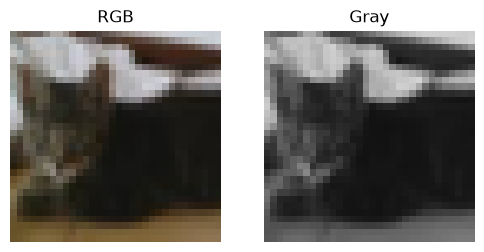

In [ ]:
LUMA = np.array([0.299, 0.587, 0.114]) # Luminanace

def to_gray(img):
    # Weighted sum over the channel axis, rounded to uint8
    return np.round(img[..., :3] @ LUMA).astype(np.uint8)

gray = to_gray(sample)

fig, ax = plt.subplots(1, 2, figsize=(6, 3))
ax[0].imshow(sample); ax[0].set_title('RGB')
ax[1].imshow(gray, cmap='gray', vmin=0, vmax=255); ax[1].set_title('Gray')
for a in ax: a.axis('off')
plt.show()

## 2. Gamma correction

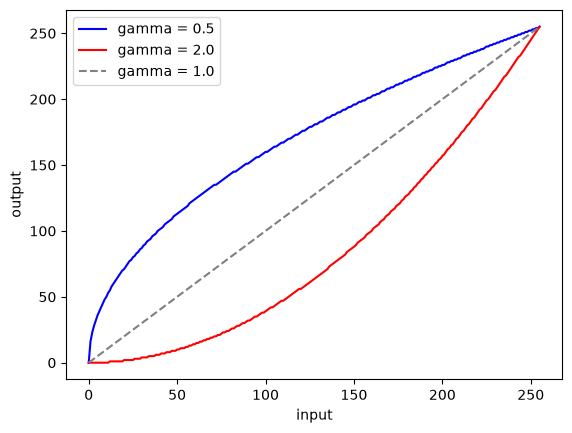

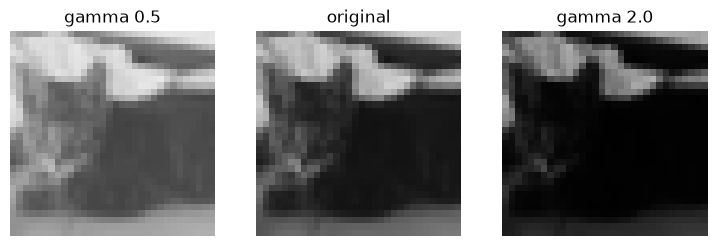

In [3]:
def gamma_correct(img, gamma, c=1.0):
    # Normalize to [0, 1], apply power law, scale back to [0, 255]
    out = c * 255 * (img / 255.0) ** gamma
    return np.clip(np.round(out), 0, 255).astype(np.uint8)

levels = np.arange(256)
plt.plot(levels, gamma_correct(levels, 0.5), color='blue', label='gamma = 0.5')
plt.plot(levels, gamma_correct(levels, 2.0), color='red', label='gamma = 2.0')
plt.plot(levels, levels, color='gray', linestyle='--', label='gamma = 1.0')
plt.xlabel('input'); plt.ylabel('output'); plt.legend(); plt.show()

fig, ax = plt.subplots(1, 3, figsize=(9, 3))
for a, (title, g) in zip(ax, [('gamma 0.5', 0.5), ('original', 1.0), ('gamma 2.0', 2.0)]):
    a.imshow(gamma_correct(gray, g), cmap='gray', vmin=0, vmax=255)
    a.set_title(title); a.axis('off')
plt.show()

## 3. Histogram equalization

$$h(v) = \mathrm{round}\left(\frac{CDF(v) - CDF_{min}}{N - CDF_{min}} \times 255\right)$$

where $CDF_{min}$ is the smallest **non-zero** CDF value and $N$ is the number of pixels.

In [4]:
def equalize(gray):
    hist = np.bincount(gray.ravel(), minlength=256)
    cdf = hist.cumsum()
    cdf_min = cdf[cdf > 0].min()
    if cdf_min == gray.size:  # constant image, nothing to equalize
        return gray.copy(), np.arange(256, dtype=np.uint8)
    lut = np.round((cdf - cdf_min) / (gray.size - cdf_min) * 255).astype(np.uint8)
    return lut[gray], lut  # lut[gray] = fancy indexing, remaps every pixel

eq, lut = equalize(gray)

In [ ]:
?np.bincount

Signature:       np.bincount(x, /, weights=None, minlength=0)
Call signature:  np.bincount(*args, **kwargs)
Type:            _ArrayFunctionDispatcher
String form:     <built-in function bincount>
Docstring:      
bincount(x, /, weights=None, minlength=0)

Count number of occurrences of each value in array of non-negative ints.

The number of bins (of size 1) is one larger than the largest value in
`x`. If `minlength` is specified, there will be at least this number
of bins in the output array (though it will be longer if necessary,
depending on the contents of `x`).
Each bin gives the number of occurrences of its index value in `x`.
If `weights` is specified the input array is weighted by it, i.e. if a
value ``n`` is found at position ``i``, ``out[n] += weight[i]`` instead
of ``out[n] += 1``.

Parameters
----------
x : array_like, 1 dimension, nonnegative ints
    Input array.
weights : array_like, optional
    Weights, array of the same shape as `x`.
minlength : int, optional
    A mi

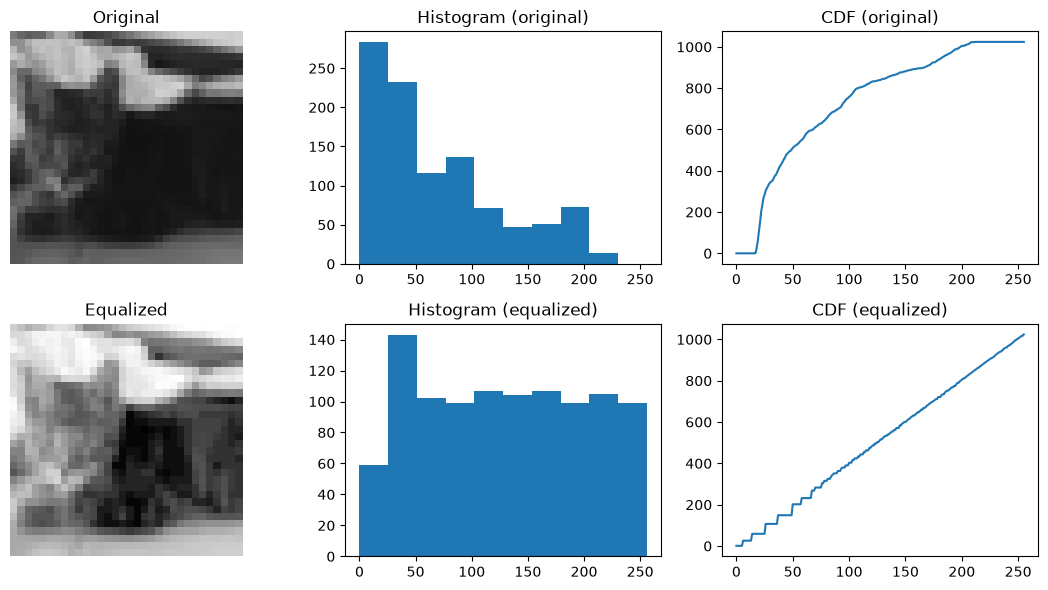

In [6]:
fig, ax = plt.subplots(2, 3, figsize=(11, 6))

ax[0, 0].imshow(gray, cmap='gray', vmin=0, vmax=255); ax[0, 0].set_title('Original')
ax[0, 1].hist(gray.ravel(), range=(0, 256)); ax[0, 1].set_title('Histogram (original)')
ax[0, 2].plot(np.bincount(gray.ravel(), minlength=256).cumsum()); ax[0, 2].set_title('CDF (original)')

ax[1, 0].imshow(eq, cmap='gray', vmin=0, vmax=255); ax[1, 0].set_title('Equalized')
ax[1, 1].hist(eq.ravel(), range=(0, 256)); ax[1, 1].set_title('Histogram (equalized)')
ax[1, 2].plot(np.bincount(eq.ravel(), minlength=256).cumsum()); ax[1, 2].set_title('CDF (equalized)')

ax[0, 0].axis('off'); ax[1, 0].axis('off')
plt.tight_layout(); plt.show()

## 4. Sanity check against OpenCV (optional)

In [7]:
try:
    import cv2
    ref = cv2.equalizeHist(gray)
    print('max abs diff vs cv2.equalizeHist:', np.abs(ref.astype(int) - eq.astype(int)).max())
except ImportError:
    print('cv2 not installed: pip install opencv-python')

max abs diff vs cv2.equalizeHist: 0


In [8]:
import cv2

def equalize_rgb(img):
    ycrcb = cv2.cvtColor(img, cv2.COLOR_RGB2YCrCb)
    ycrcb[..., 0], _ = equalize(ycrcb[..., 0])   # chỉ cân bằng kênh Y (độ sáng)
    return cv2.cvtColor(ycrcb, cv2.COLOR_YCrCb2RGB)

In [9]:
!pip install opencv-python

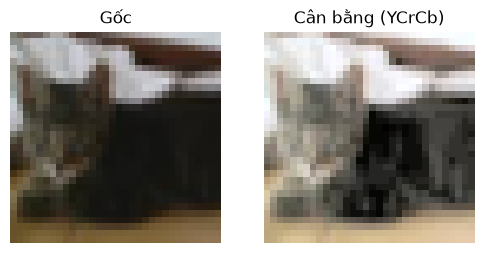

In [10]:
eq_rgb = equalize_rgb(sample)

fig, ax = plt.subplots(1, 2, figsize=(6, 3))
ax[0].imshow(sample);  ax[0].set_title('Gốc')
ax[1].imshow(eq_rgb);  ax[1].set_title('Cân bằng (YCrCb)')
for a in ax: a.axis('off')
plt.show()

In [11]:
eq_naive = np.stack([equalize(sample[..., c])[0] for c in range(3)], axis=-1)

In [12]:
x_train_eq = np.stack([equalize_rgb(im) for im in x_train])   # (50000, 32, 32, 3)

In [20]:
input_image = np.random.rand(5,5)*100
input_image = input_image.astype(int)

In [21]:
input_image

array([[80, 33, 47, 66, 63],
       [59, 32, 61, 24, 82],
       [45, 17, 66, 52, 99],
       [97, 42, 33, 99, 95],
       [47, 51, 80, 64, 52]])

In [ ]:
v